# ЗАДАЧА 1: Загрузка модели с attention

In [2]:
model_name = "distilbert-base-uncased"

In [3]:
from transformers import AutoModel

model = AutoModel.from_pretrained(
    model_name,
    output_attentions=True  # важно!
)
model.eval()

W1030 16:06:44.016000 67686 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 9736.99it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [6]:
#грузим токенизатор
from transformers import AutoModel
from transformers import AutoTokenizer
import torch
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [7]:
text = "The amazing movie won many awards"
tokens = tokenizer(text, return_tensors="pt")

# ЗАДАЧА 2: Получение attention весов

In [8]:
with torch.no_grad():
    outputs = model(**tokens)

In [9]:
print(type(outputs.attentions))
print(f'Количество слоёв: {len(outputs.attentions)}')
print(f'Форма attention для слоя 0: {outputs.attentions[0].shape}')

<class 'tuple'>
Количество слоёв: 6
Форма attention для слоя 0: torch.Size([1, 12, 8, 8])


In [10]:
attention = outputs.attentions[0]  # первый слой
print(f'Attention shape: {attention.shape}')

# Для первого батча, первой головы
attn_single = attention[0, 0]  # [seq_len, seq_len]
print(f'Single head shape: {attn_single.shape}')

Attention shape: torch.Size([1, 12, 8, 8])
Single head shape: torch.Size([8, 8])


In [ ]:
attention = outputs.attentions[0]  # первый слой
print(f'Attention shape: {attention.shape}')

# Для первого батча, первой головы
attn_single = attention[0, 0]  # [seq_len, seq_len]
print(f'Single head shape: {attn_single.shape}')

Attention shape: torch.Size([1, 12, 8, 8])
Single head shape: torch.Size([8, 8])


# ЗАДАЧА 3: Визуализация attention

In [13]:
pip install matplotlib seaborn


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


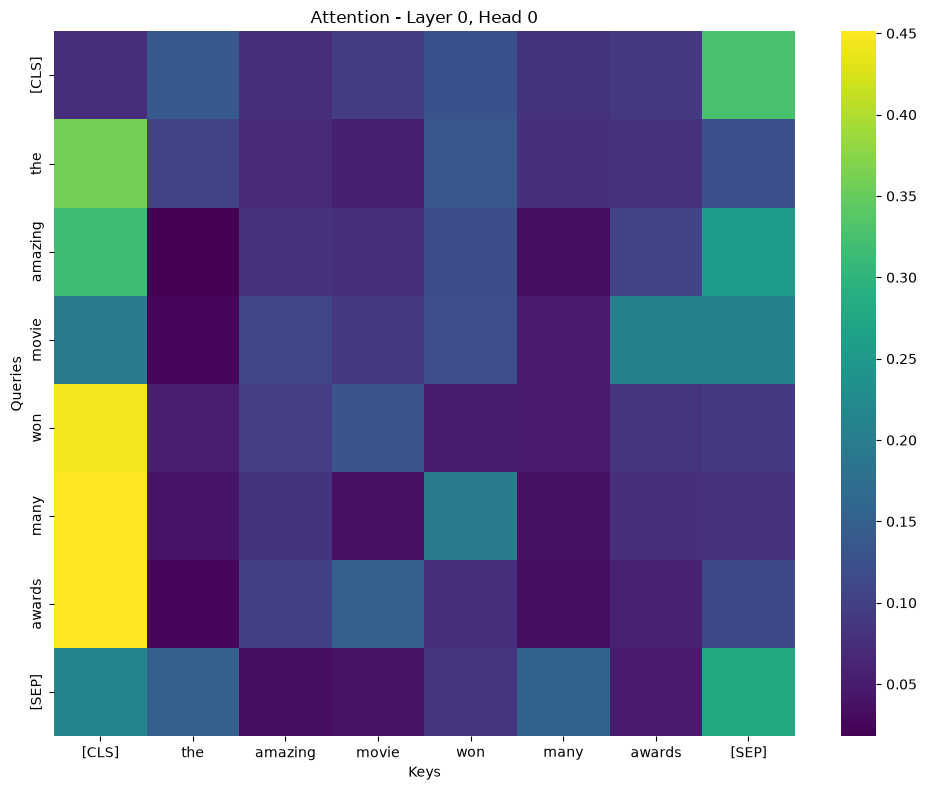

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def visualize_attention(tokens, attention, layer=0, head=0):
    """
    tokens: токенизированный текст
    attention: attention weights от модели
    layer: номер слоя для визуализации
    head: номер головы для визуализации
    """
    # Получаем attention матрицу
    attn = attention[layer][0, head]  # [seq_len, seq_len]

    # Получаем токены для подписей
    token_list = tokenizer.convert_ids_to_tokens(tokens['input_ids'][0])

    # Рисуем heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        attn.cpu().numpy(),
        xticklabels=token_list,
        yticklabels=token_list,
        cmap='viridis',
        cbar=True
    )
    plt.title(f'Attention - Layer {layer}, Head {head}')
    plt.xlabel('Keys')
    plt.ylabel('Queries')
    plt.tight_layout()
    plt.savefig(f'attention_layer{layer}_head{head}.png')
    plt.show()

# Используйте:
visualize_attention(tokens, outputs.attentions, layer=0, head=0)

# ЗАДАЧА 4: Анализ attention для разных слоёв

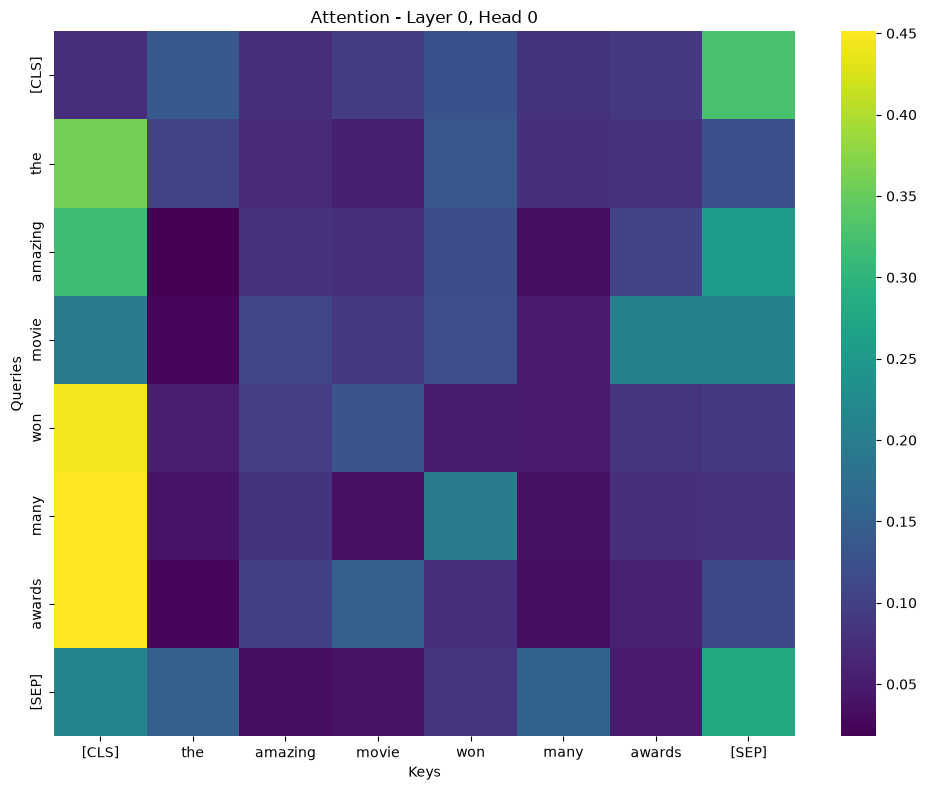

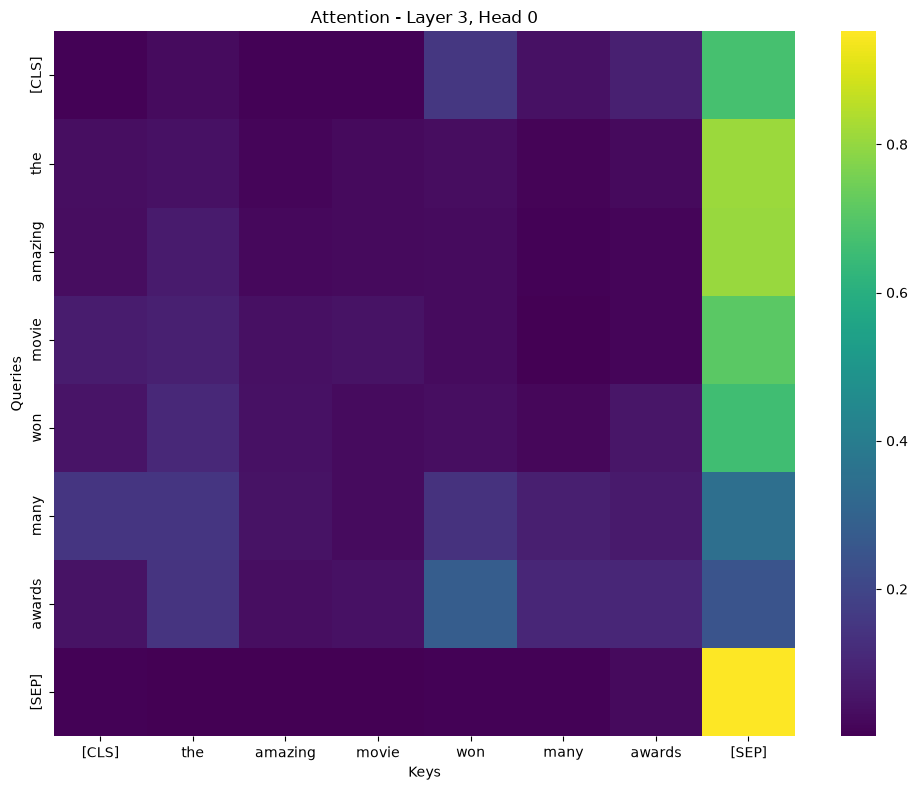

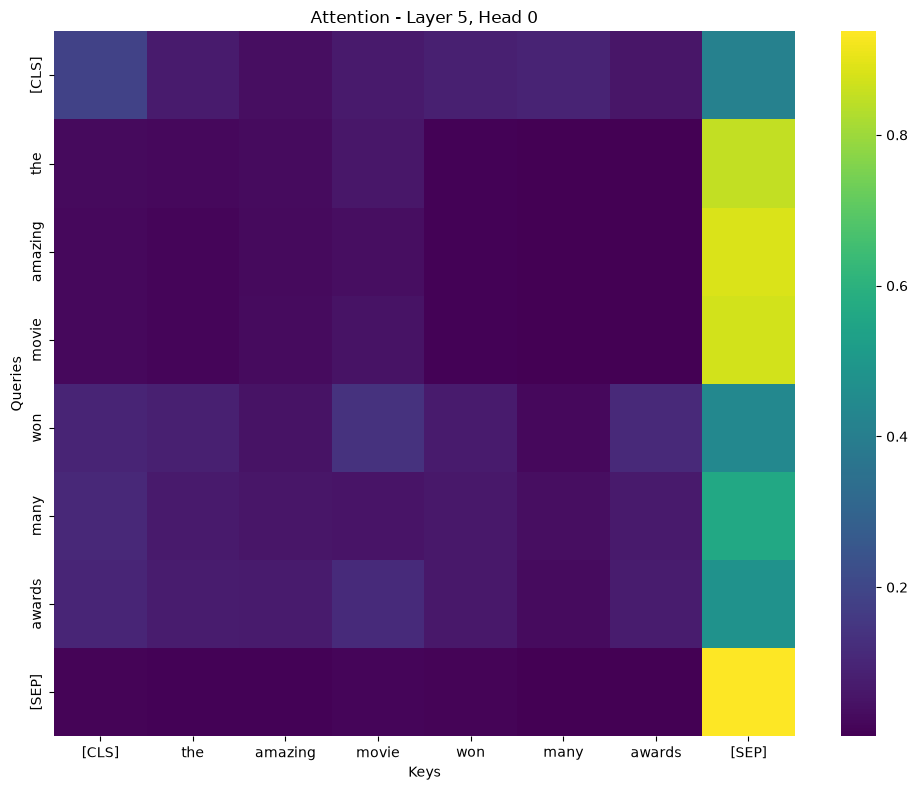

In [15]:
# Первый слой
visualize_attention(tokens, outputs.attentions, layer=0, head=0)

# Средний слой
visualize_attention(tokens, outputs.attentions, layer=3, head=0)

# Последний слой
visualize_attention(tokens, outputs.attentions, layer=5, head=0)

# ЗАДАЧА 5: Attention для разных голов

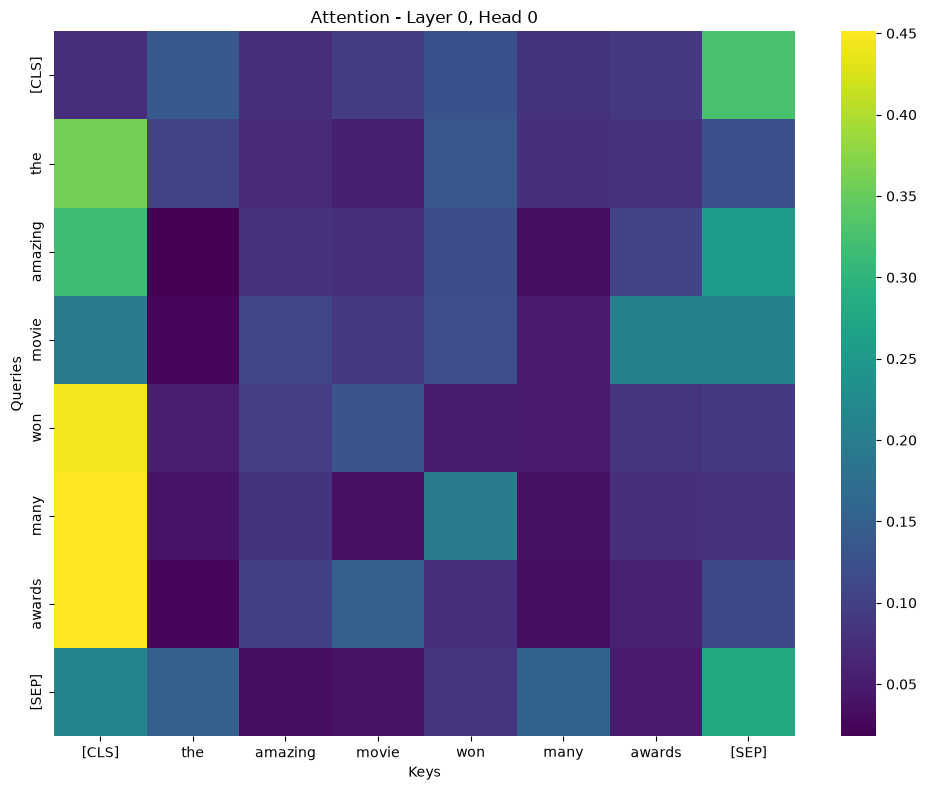

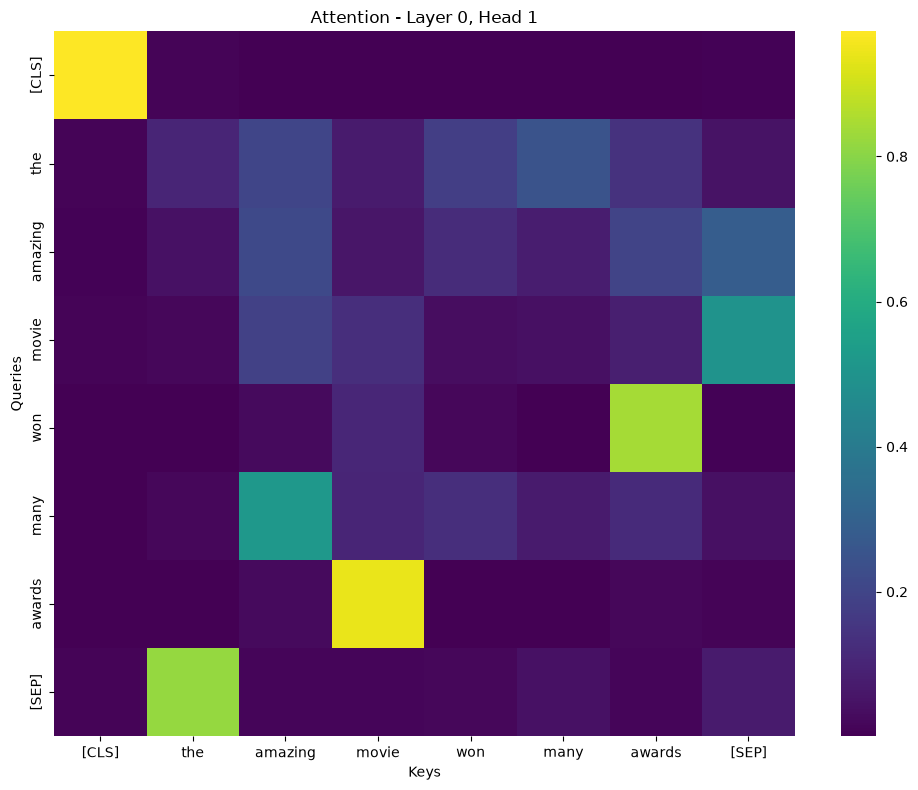

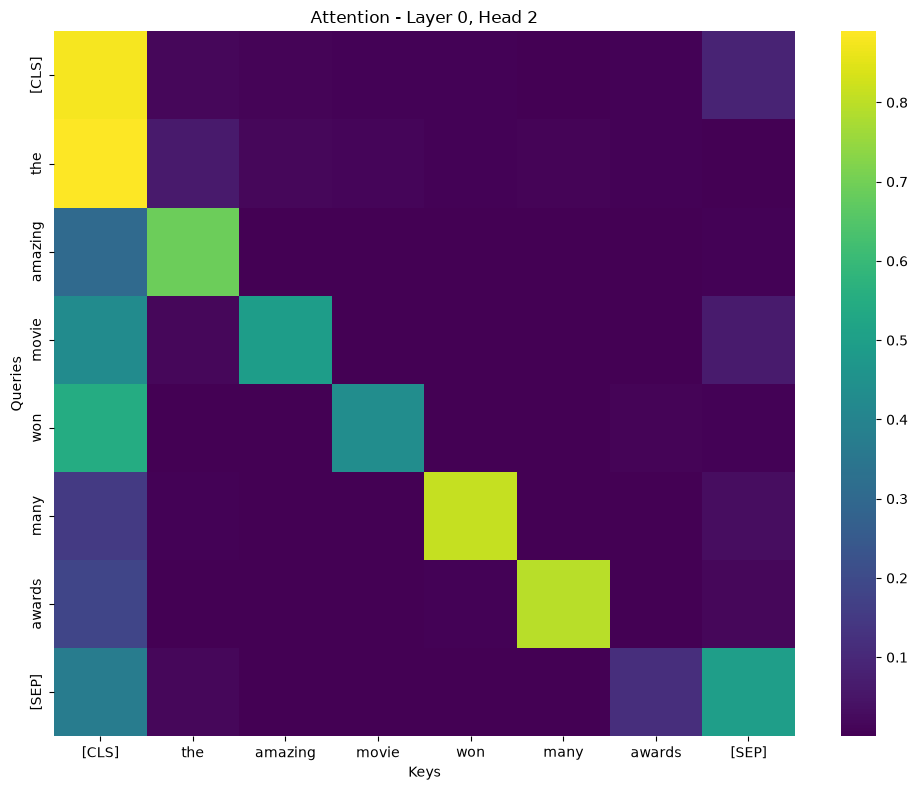

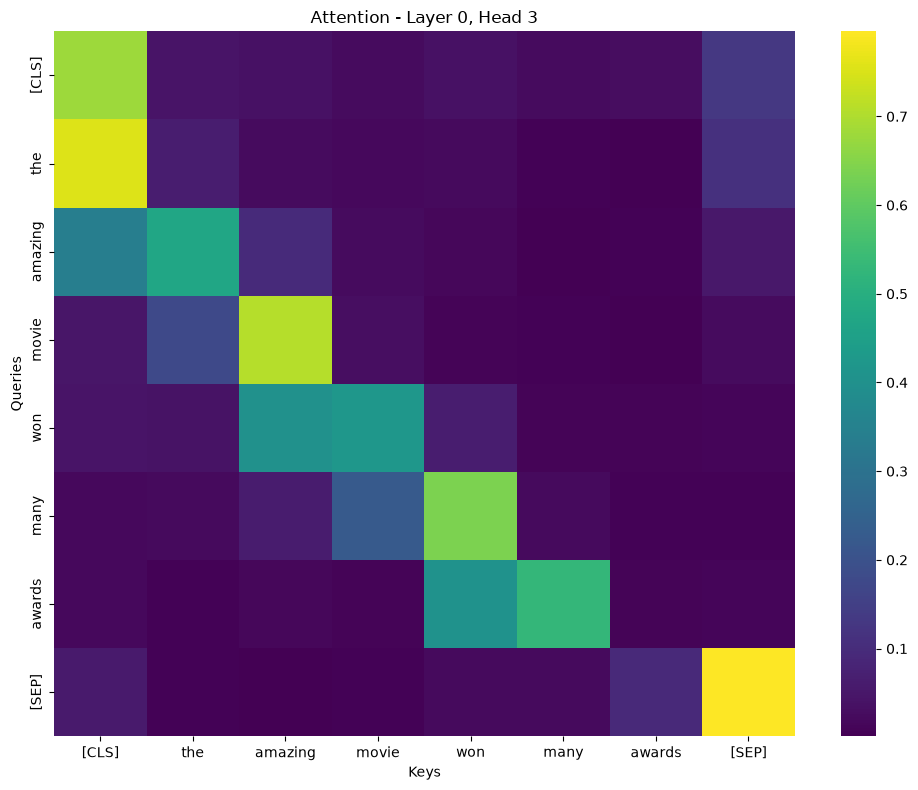

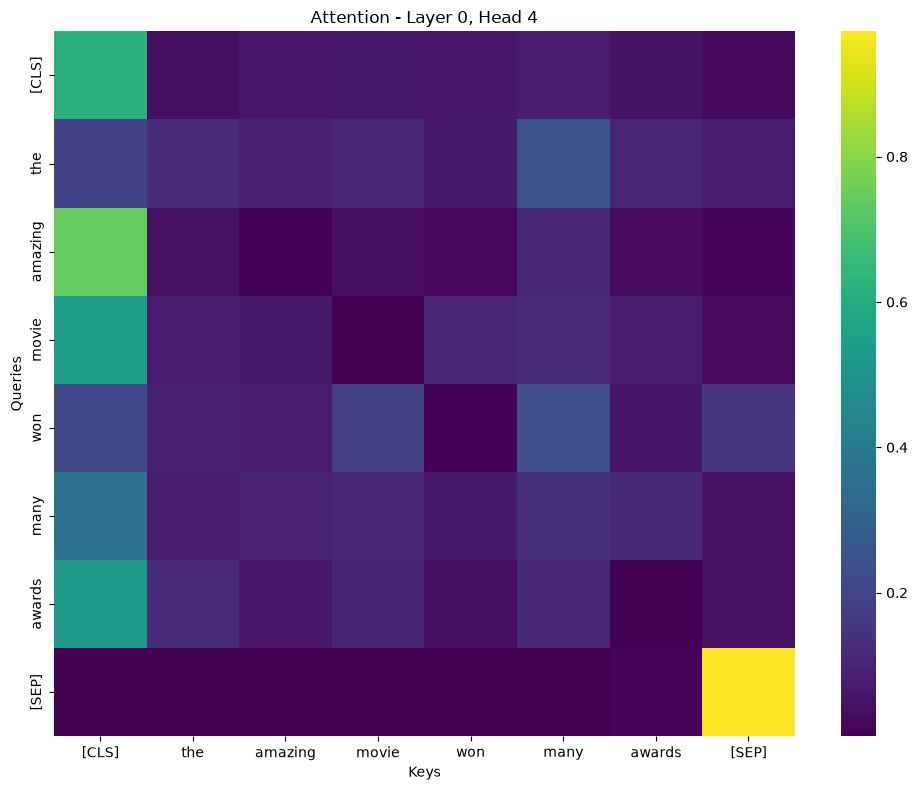

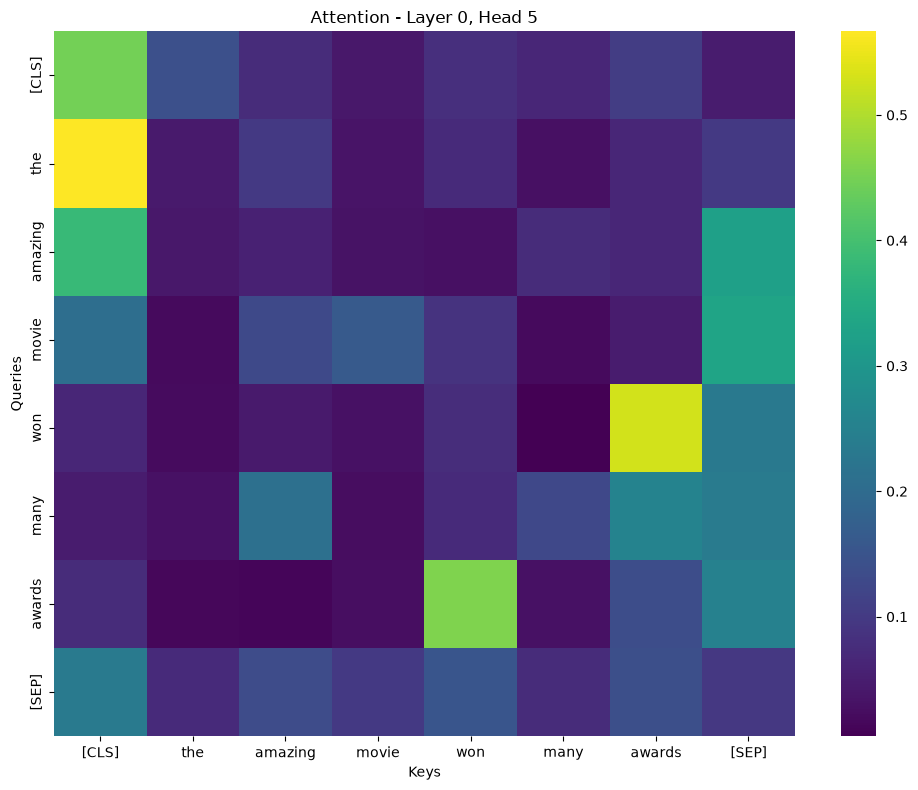

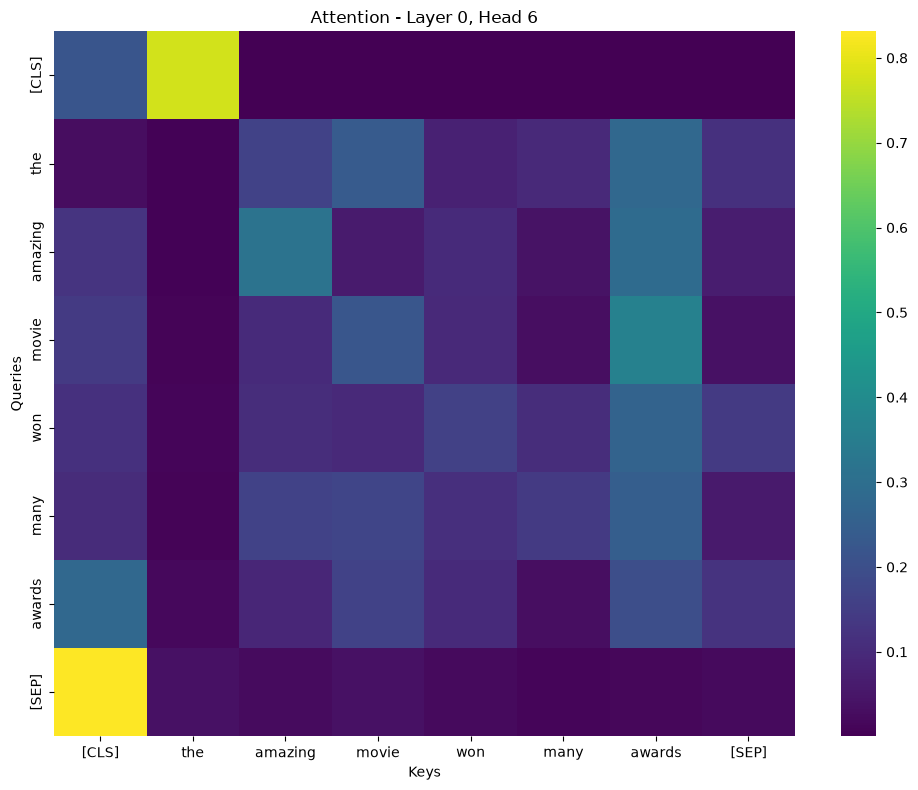

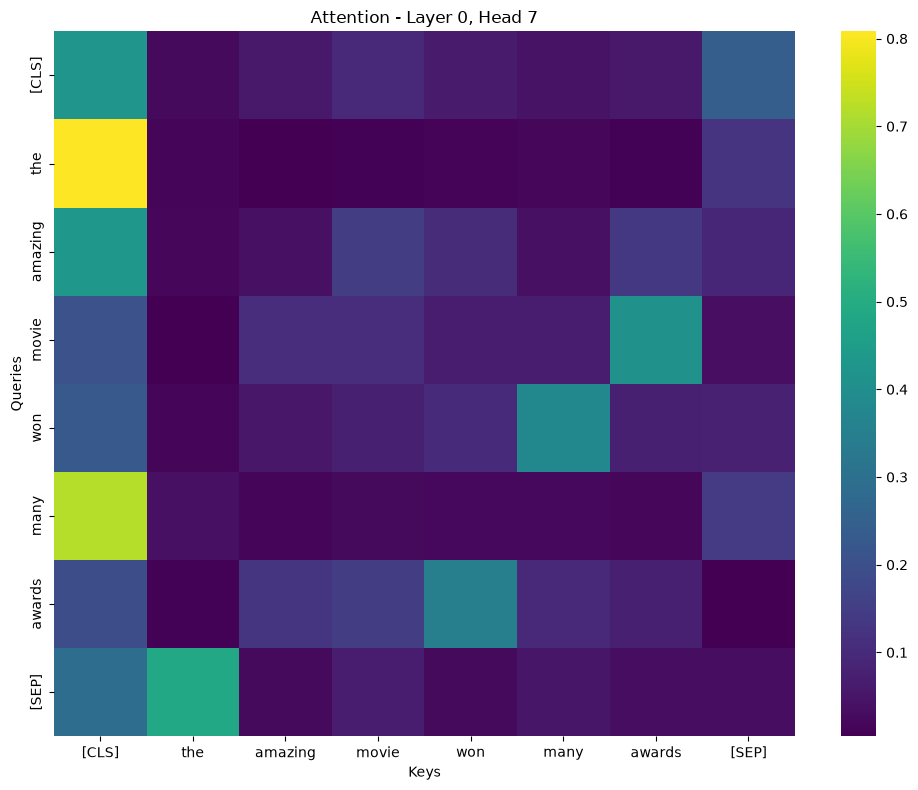

In [16]:
for head in range(8):  # DistilBERT имеет 8 голов
    visualize_attention(tokens, outputs.attentions, layer=0, head=head)

# ЗАДАЧА 6: Анализ внимания к ключевым словам

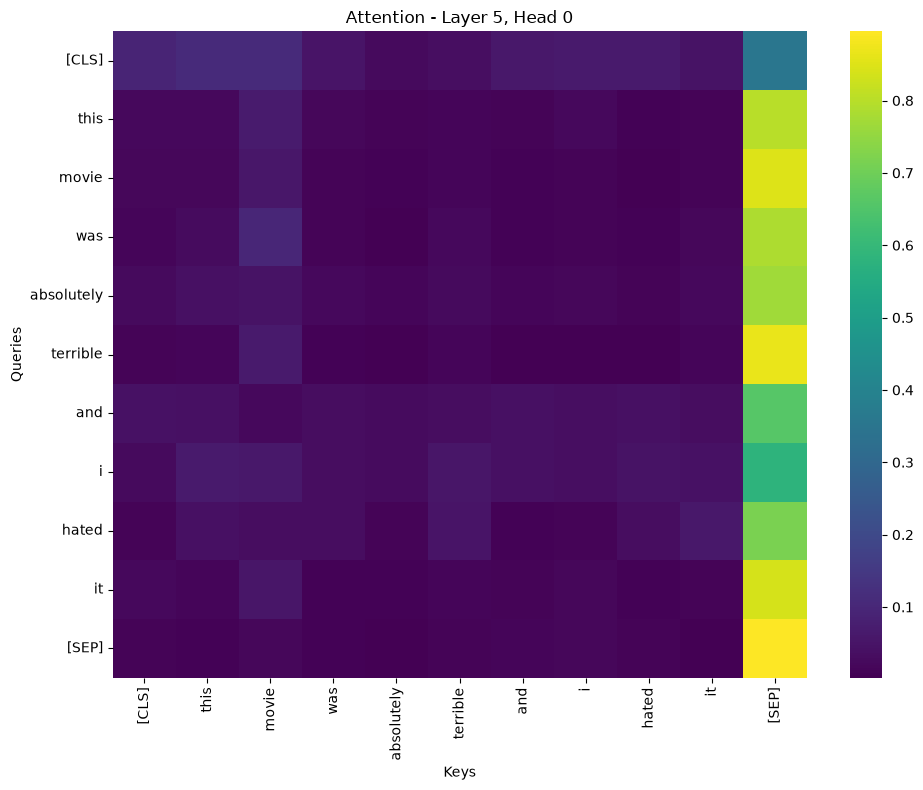

In [17]:
text = "This movie was absolutely terrible and I hated it"
tokens = tokenizer(text, return_tensors="pt")

with torch.no_grad():
    outputs = model(**tokens)

# Визуализируйте
visualize_attention(tokens, outputs.attentions, layer=5, head=0)

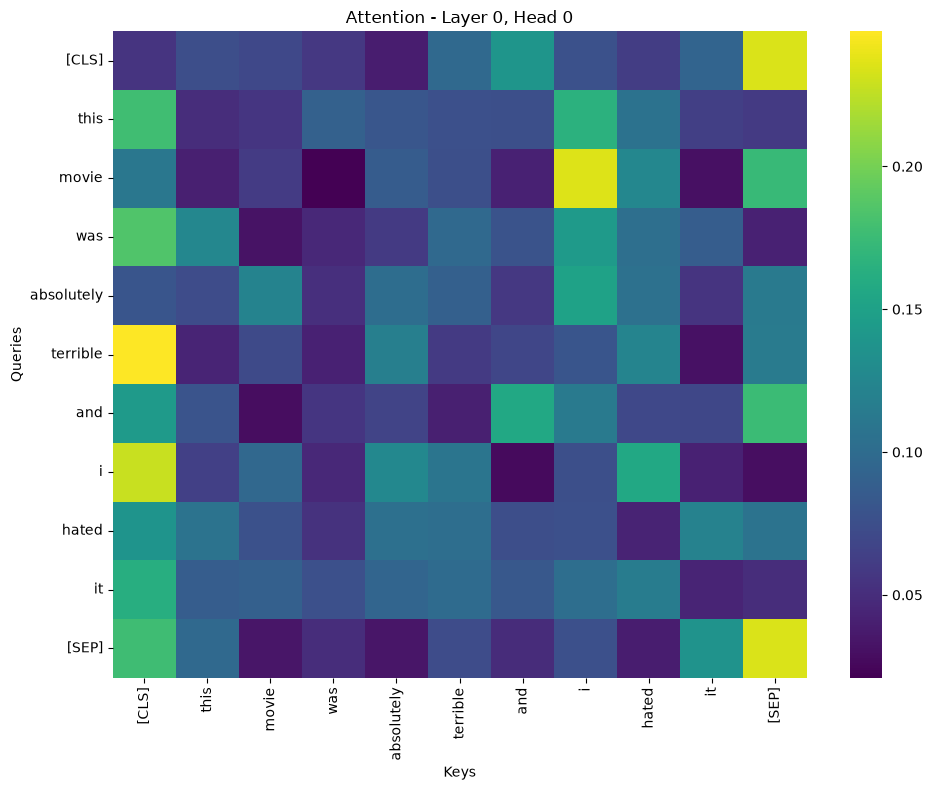

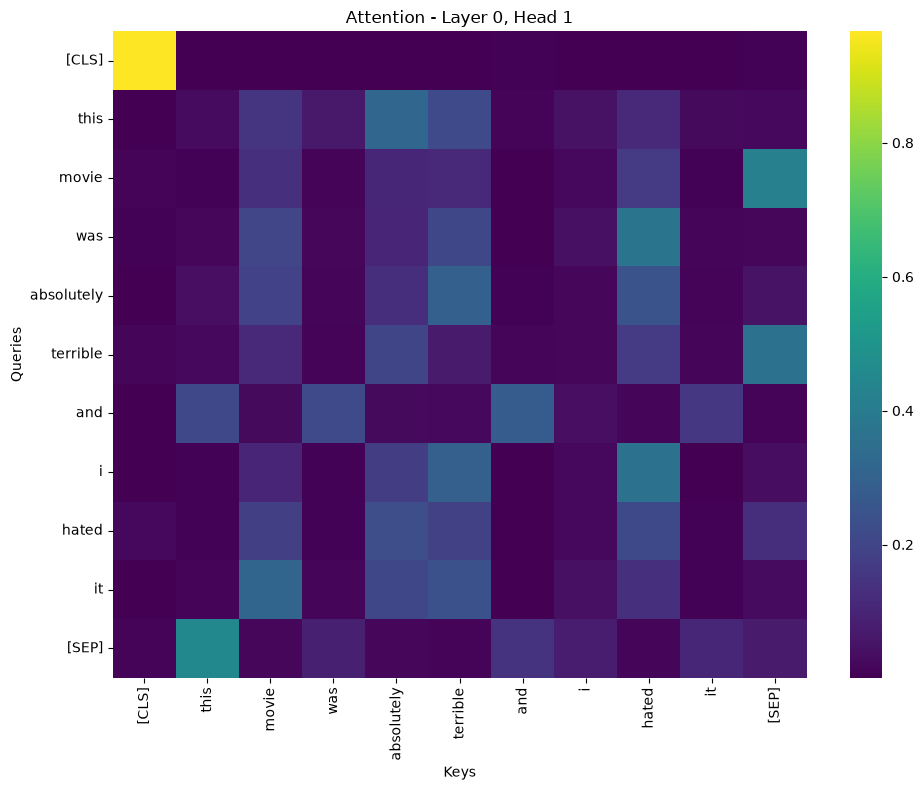

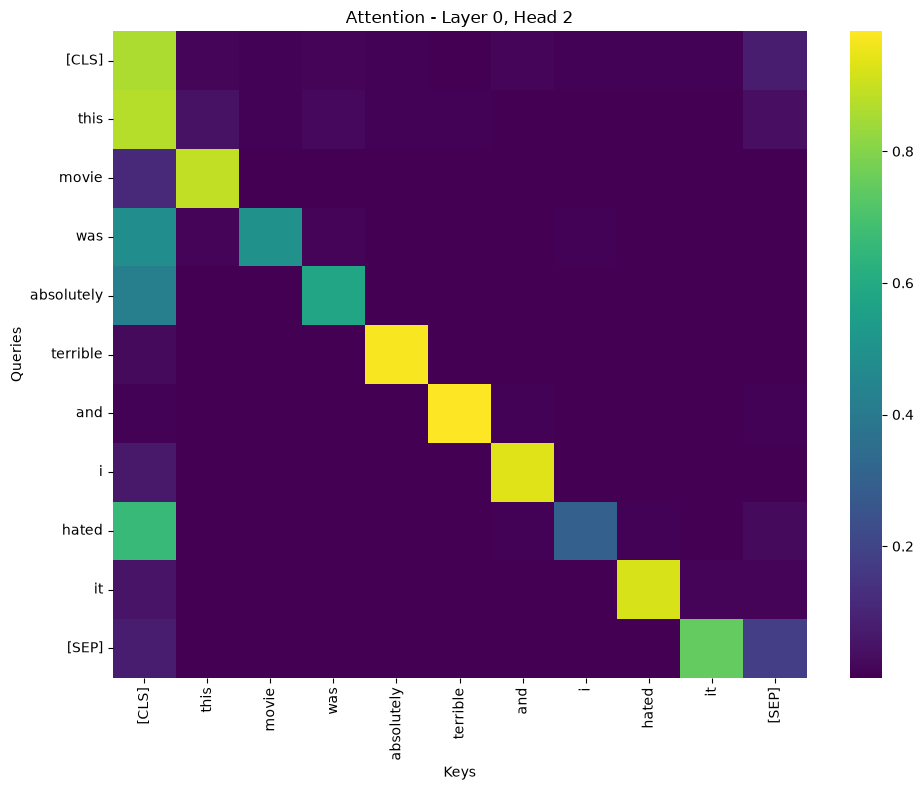

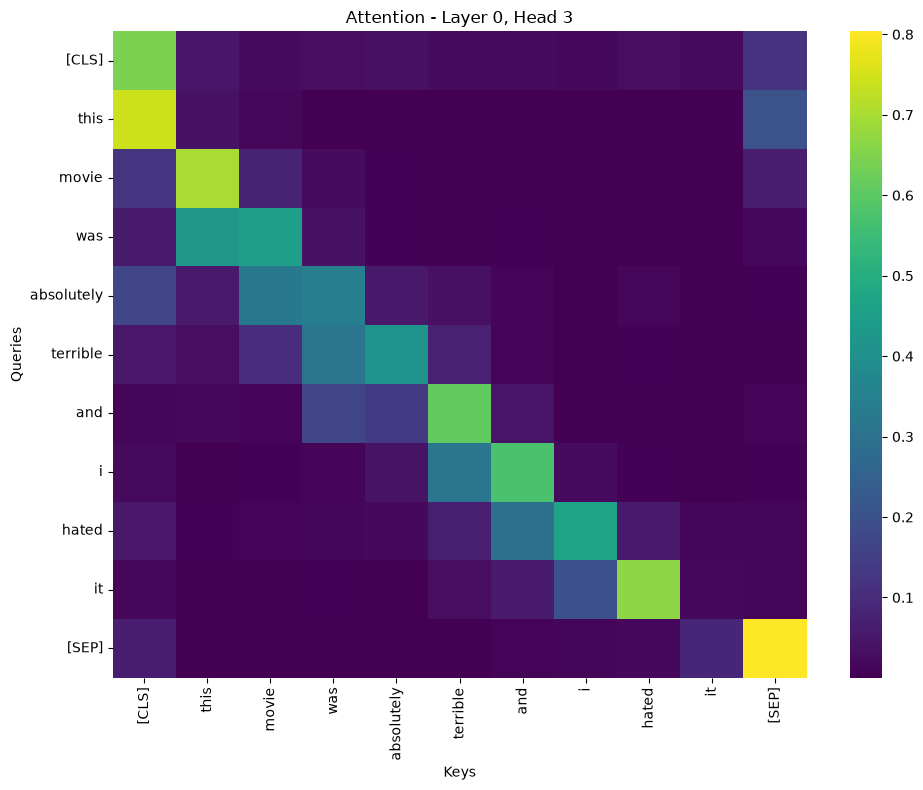

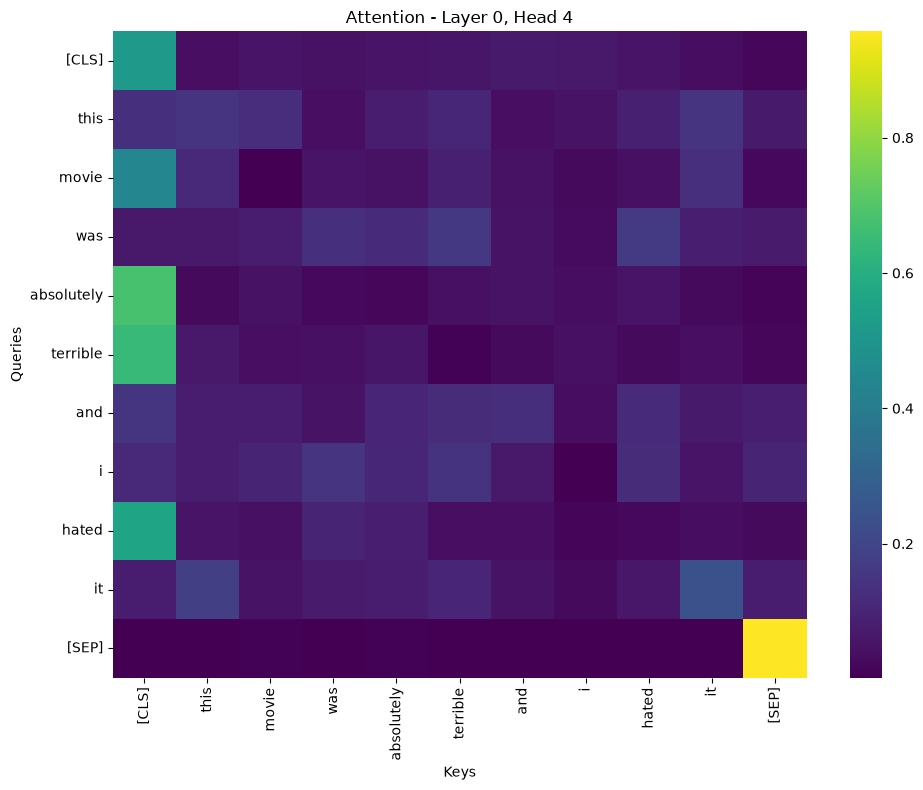

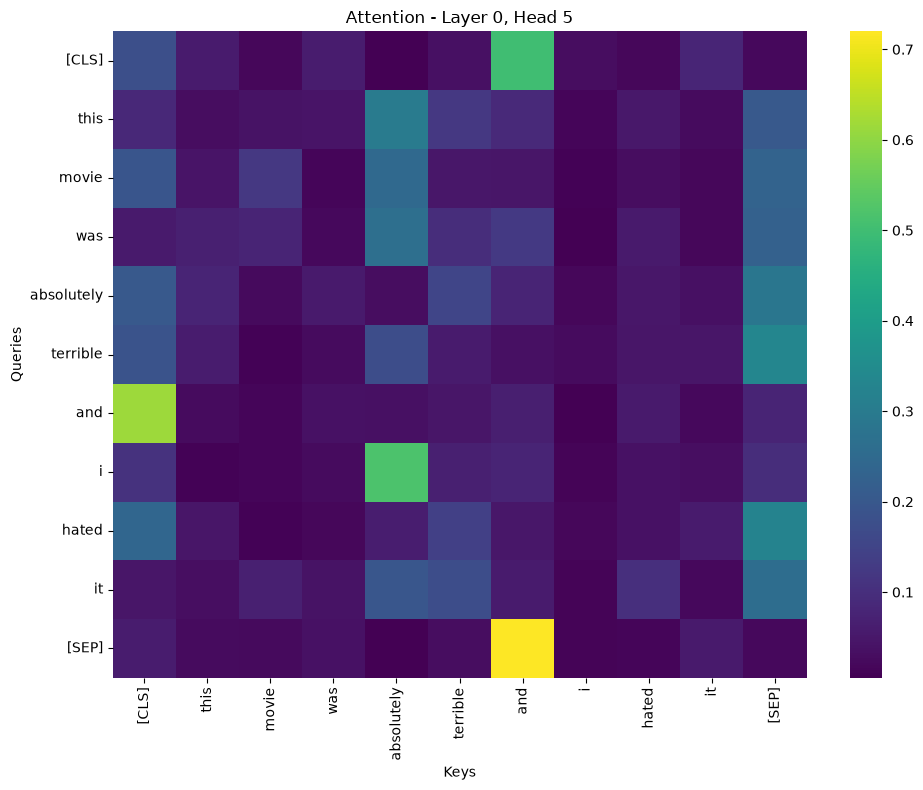

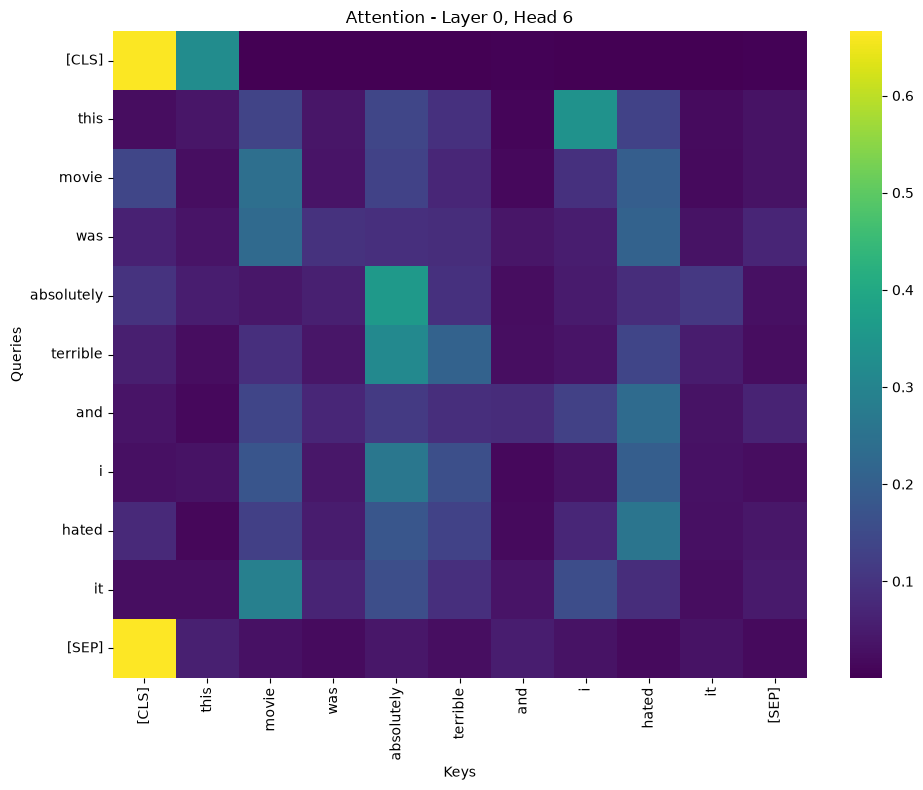

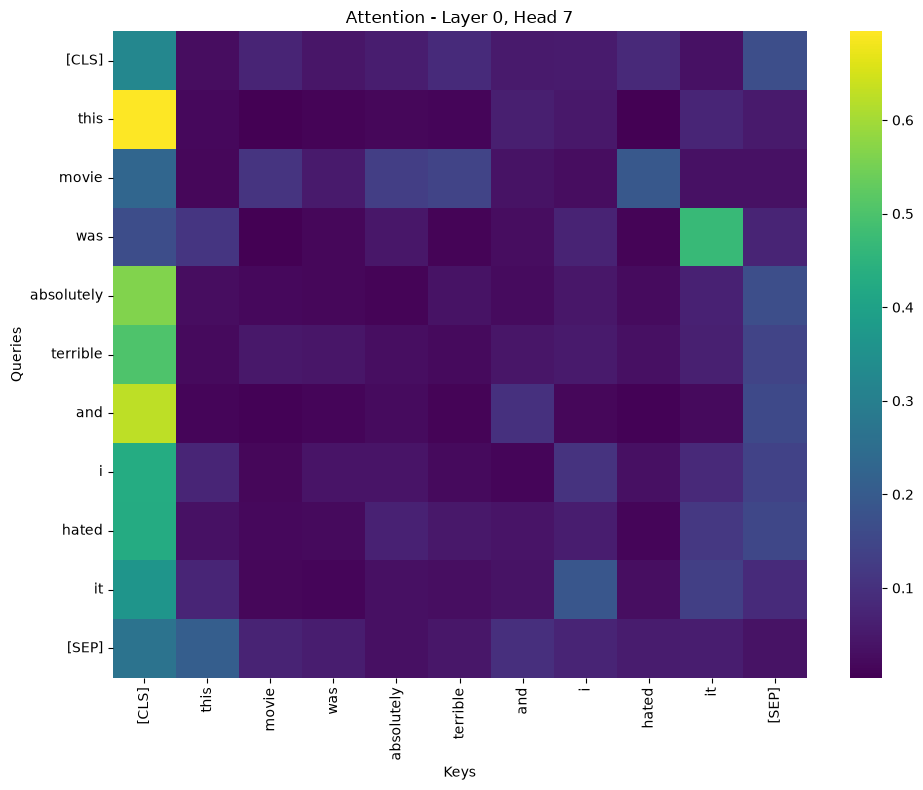

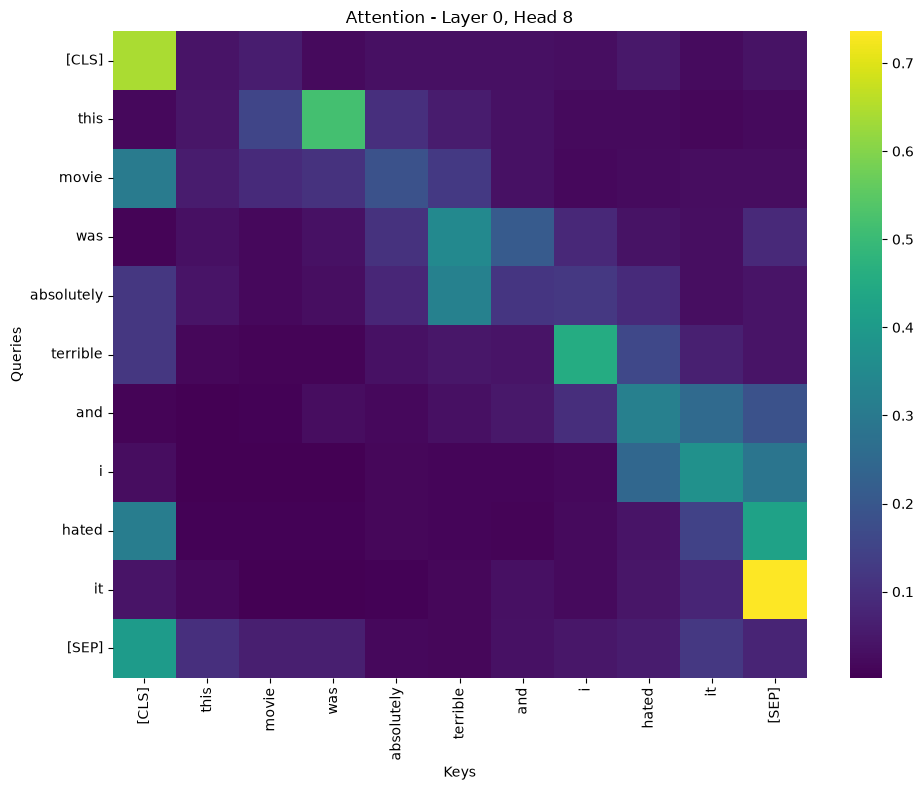

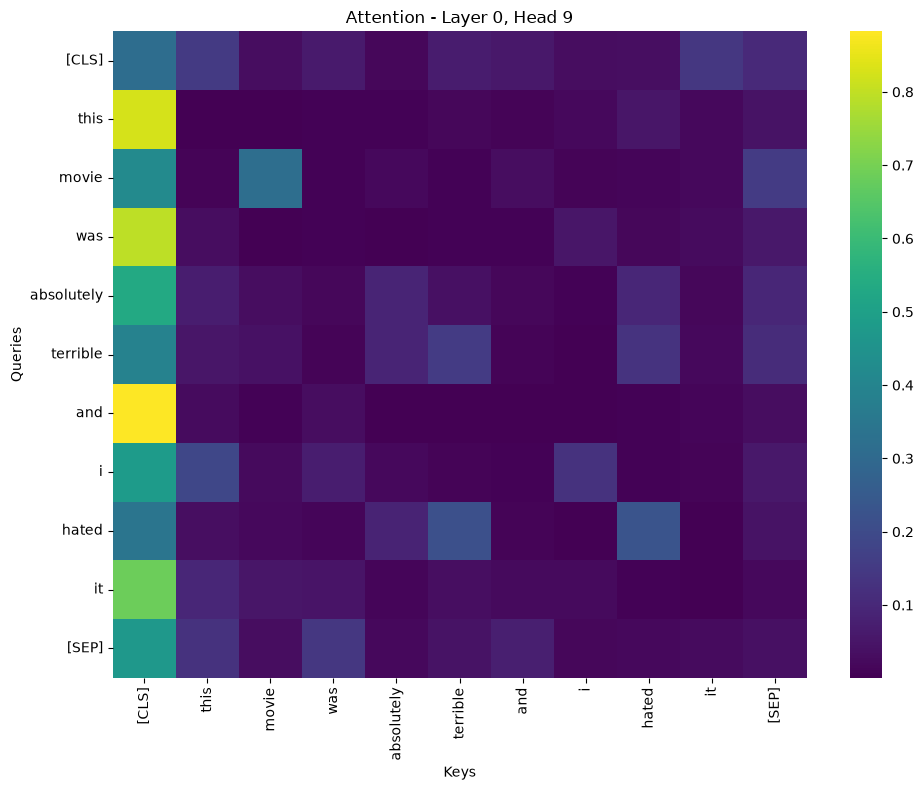

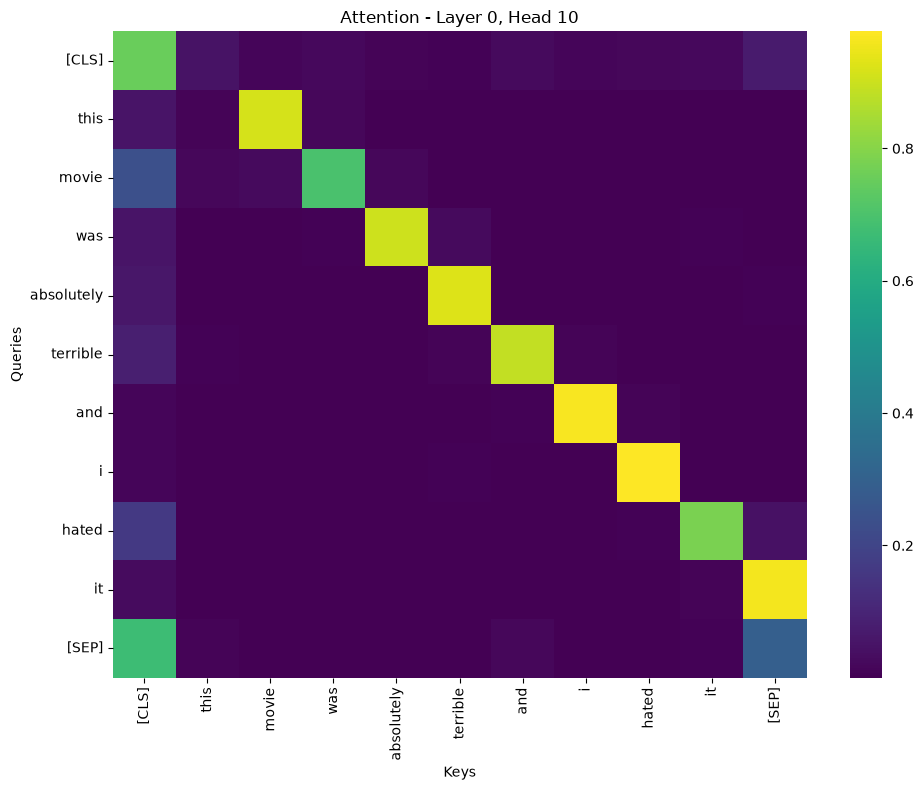

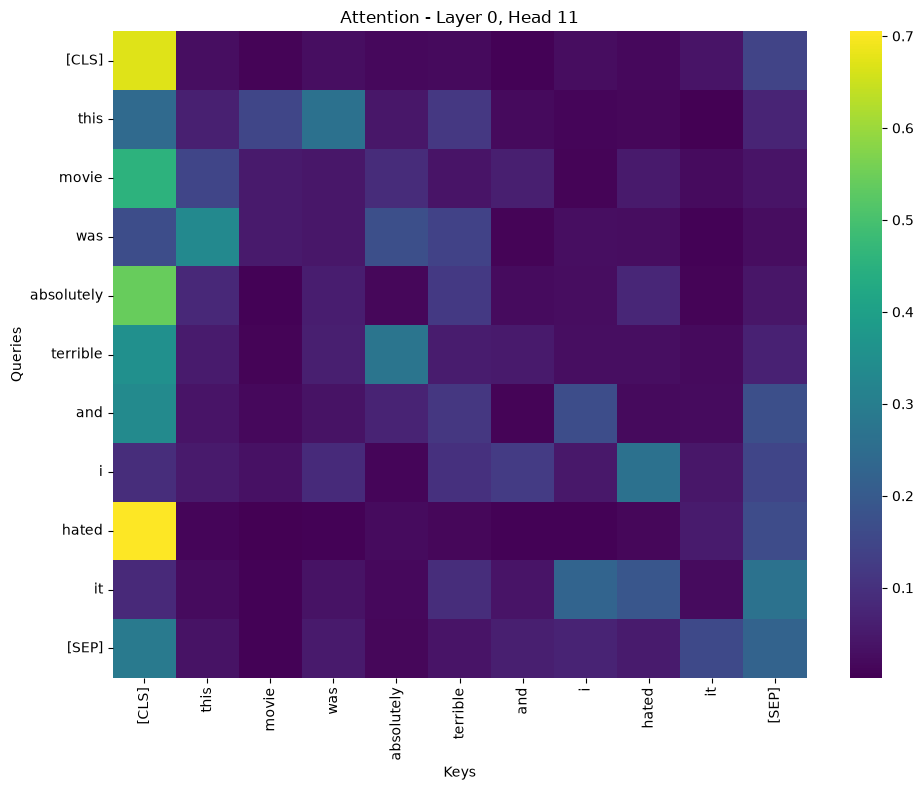

In [18]:
for head in range(model.config.n_heads):   # 12
    visualize_attention(tokens, outputs.attentions, layer=0, head=head)

In [19]:
token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"][0])
i = token_list.index("terrible")

for head in range(model.config.n_heads):
    row = outputs.attentions[5][0, head, i].clone()
    row[[0, -1]] = 0                      # убираем [CLS] и [SEP]
    top = row.topk(2)
    words = [token_list[j] for j in top.indices]
    print(head, words, top.values.round(decimals=2).tolist())

0 ['movie', 'this'] [0.05999999865889549, 0.019999999552965164]
1 ['was', 'this'] [0.07000000029802322, 0.03999999910593033]
2 ['it', 'was'] [0.05000000074505806, 0.03999999910593033]
3 ['movie', 'terrible'] [0.05999999865889549, 0.03999999910593033]
4 ['terrible', 'hated'] [0.12999999523162842, 0.07999999821186066]
5 ['terrible', 'this'] [0.10999999940395355, 0.07999999821186066]
6 ['hated', 'absolutely'] [0.07999999821186066, 0.07000000029802322]
7 ['terrible', 'movie'] [0.019999999552965164, 0.019999999552965164]
8 ['terrible', 'this'] [0.23999999463558197, 0.07000000029802322]
9 ['and', 'absolutely'] [0.07000000029802322, 0.05999999865889549]
10 ['this', 'terrible'] [0.07999999821186066, 0.05999999865889549]
11 ['terrible', 'movie'] [0.03999999910593033, 0.03999999910593033]


In [21]:
for head in range(model.config.n_heads):
    row = outputs.attentions[5][0, head, i].clone()
    row[[0, -1]] = 0                      # убираем [CLS] и [SEP]
    top = row.topk(2)
    words = [token_list[j] for j in top.indices]
    print(head, words, [round(v, 2) for v in top.values.tolist()])   # ← вот эта строка

0 ['movie', 'this'] [0.06, 0.02]
1 ['was', 'this'] [0.07, 0.04]
2 ['it', 'was'] [0.05, 0.04]
3 ['movie', 'terrible'] [0.06, 0.04]
4 ['terrible', 'hated'] [0.13, 0.08]
5 ['terrible', 'this'] [0.11, 0.08]
6 ['hated', 'absolutely'] [0.08, 0.07]
7 ['terrible', 'movie'] [0.02, 0.02]
8 ['terrible', 'this'] [0.24, 0.07]
9 ['and', 'absolutely'] [0.07, 0.06]
10 ['this', 'terrible'] [0.08, 0.06]
11 ['terrible', 'movie'] [0.04, 0.04]
